# Source Localization — Load Paper (Simple condition)

sLORETA source localization using fsaverage template brain.
One figure per paradigm (active / passive) showing all components.

**Condition:** Simple only (oddball runs)  
**Method:** sLORETA via MNE minimum norm  
**Template:** fsaverage (no individual MRI)  
**Montage:** standard_1020 (approximation for WaveGuard 64ch)


In [5]:
from datetime import datetime
from pathlib import Path
import sys
import pickle
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import mne
from mne.datasets import fetch_fsaverage
from mne.minimum_norm import make_inverse_operator, apply_inverse
from scipy import stats
import time

def find_repo_root(marker="core") -> Path:
    """Walk up from the current directory until a folder containing
    `marker` (e.g. core/) is found -- avoids hardcoding folder depth,
    which breaks every time notebooks get moved."""
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / marker).is_dir():
            return candidate
    raise RuntimeError(f"Could not locate repo root (no '{marker}/' found above {Path.cwd()})")

sys.path.insert(0, str(find_repo_root()))
from core.participants import get_participants

# ==============================================================================
# CONFIGURATION
# ==============================================================================

PARADIGM    = "active"   # "active" | "passive"
TRIALS      = "correct"  # "correct" (primary) | "alltrials" — stimulus-locked pkls
DATE_SOURCE = None       # None = latest pkl in raw/{TRIALS}/; or pin, e.g. "20261031"
SNR         = 3.0        # signal-to-noise ratio for inverse solution
LAMBDA2     = 1.0 / SNR ** 2
METHOD      = "sLORETA"
STUDY = "Active" if PARADIGM == "active" else "Passive"

if sys.platform == "win32":
    root     = Path(f"L:/EEG_Flow_data/Study_EEG_Flow_{STUDY}/derivatives_v2/outputs")
    root_img = Path(f"L:/EEG_Flow_data/Study_EEG_Flow_{STUDY}/derivatives_v2/outputs/img/source_localization")
else:
    root     = Path(f"/Volumes/faculty/EEG_Flow_data/Study_EEG_Flow_{STUDY}/derivatives_v2/outputs")
    root_img = Path(f"/Volumes/faculty/EEG_Flow_data/Study_EEG_Flow_{STUDY}/derivatives_v2/outputs/img/source_localization")

root_img = root_img / TRIALS   # figures kept apart per trial variant
root_img.mkdir(parents=True, exist_ok=True)
DATE_STR = datetime.today().strftime("%Y%m%d")

included = list(get_participants("load", PARADIGM).keys())
n        = len(included)
n_source = n   # pkl names carry the included N (Load passive: 46 since S39 was excluded)

DEVIANT = "target" if PARADIGM == "active" else "deviant"

print(f"Paradigm: {PARADIGM.upper()} | N={n}")
print(f"Output: {root_img}")


Paradigm: ACTIVE | N=48
Output: L:\EEG_Flow_data\Study_EEG_Flow_Active\derivatives_v2\outputs\img\source_localization\correct


In [6]:
# sample code for plotting the source estimate object (sloreta) method
# get the thresholds for the p-values
n_subjects = 48 # define the number of subjects
p_low = 0.01 # define the p-value for the lower threshold
p_high = 0.0001 # define the p-value for the higher threshold
thr_low = float("{:.2f}".format(-stats.distributions.t.ppf(p_low / 2., n_subjects - 1)))
thr_high = float("{:.2f}".format(-stats.distributions.t.ppf(p_high / 2., n_subjects - 1)))

# Threshold range (fmin, fmax, fmid) for plotting, fill up the x values
fmin = thr_low
fmax = thr_high
fmid = (thr_low + thr_high) / 2

# color values for plotting
clim = dict(kind='value', pos_lims=[fmin, fmid, fmax])

In [7]:
# ==============================================================================
# Component definitions — windows for averaging
# ==============================================================================

if PARADIGM == "active":
    COMPONENTS = [
        dict(label="N1 standard",    stim="standard",        tmin=0.090, tmax=0.130),
        # dict(label="N1 target",      stim="target",          tmin=0.090, tmax=0.130),
        # dict(label="N1 novel",       stim="novel",           tmin=0.090, tmax=0.150),
        # dict(label="MMN target",     stim="target-standard", tmin=0.130, tmax=0.190, source="diff"),
        # dict(label="MMN novel",      stim="novel-standard",  tmin=0.120, tmax=0.180, source="diff"),
        # dict(label="N2 target",      stim="target",          tmin=0.180, tmax=0.230),
        # dict(label="N2 novel",       stim="novel",           tmin=0.150, tmax=0.220),
        # dict(label="P3early target", stim="target",          tmin=0.280, tmax=0.430),
        # dict(label="P3late target",  stim="target",          tmin=0.500, tmax=0.799),
        # dict(label="P3early novel",  stim="novel",           tmin=0.180, tmax=0.270),
        # dict(label="P3late novel",   stim="novel",           tmin=0.300, tmax=0.400),
    ]
else:
    COMPONENTS = [
        # dict(label="N1 standard",    stim="standard",          tmin=0.090, tmax=0.130),
        # dict(label="N1 deviant",     stim="deviant",           tmin=0.090, tmax=0.130),
        # dict(label="N1 novel",       stim="novel",             tmin=0.090, tmax=0.150),
        # dict(label="MMN deviant",    stim="deviant-standard",  tmin=0.130, tmax=0.190, source="diff"),
        # dict(label="MMN novel",      stim="novel-standard",    tmin=0.120, tmax=0.180, source="diff"),
        # dict(label="P3early novel",  stim="novel",             tmin=0.190, tmax=0.280),
        # dict(label="P3late novel",   stim="novel",             tmin=0.300, tmax=0.380),
    ]

print(f"Components: {len(COMPONENTS)}")
for c in COMPONENTS:
    print(f"  {c['label']:20s} | {int(c['tmin']*1000)}-{int(c['tmax']*1000)}ms | {c.get('source','stim')}")


Components: 1
  N1 standard          | 90-130ms | stim


In [8]:
# ==============================================================================
# Load grand average PKLs — Simple condition only
# ==============================================================================

input_path      = root / "grand_averages" / "load" / "raw" / TRIALS
input_path_diff = root / "grand_averages" / "load" / "diff" / TRIALS
input_path_resp = root / "grand_averages" / "load" / "raw"     # response-locked: hits only, one variant

if DATE_SOURCE is None:
    _files = sorted(input_path.glob(f"*_{PARADIGM}_{n_source}p_cond-simple_stim_raw.pkl"))
    assert _files, f"No Simple stim pkl in {input_path}"
    DATE_SOURCE = _files[-1].name.split("_")[0]
print(f"DATE_SOURCE: {DATE_SOURCE} | Trials: {TRIALS}")

def load_pkl(path):
    with open(path, "rb") as f:
        return pickle.load(f)

def build_fname(cond_key, measure="raw"):
    base = f"{DATE_SOURCE}_{PARADIGM}_{n_source}p_cond-{cond_key}"
    return f"{base}_stim_{measure}.pkl"

# Load Simple condition (stim-locked raw + diff)
fname_simple = build_fname("simple", "raw")
fname_simple_diff = build_fname("simple", "diff")

print(f"Loading: {fname_simple}")
evokeds_simple = load_pkl(input_path / fname_simple)
print(f"  Keys: {list(evokeds_simple.keys())}")

if (input_path_diff / fname_simple_diff).exists():
    evokeds_simple_diff = load_pkl(input_path_diff / fname_simple_diff)
    print(f"Loading diff: {fname_simple_diff}")
    print(f"  Keys: {list(evokeds_simple_diff.keys())}")
else:
    evokeds_simple_diff = {}
    print("Diff PKL not found — MMN components will be skipped")


DATE_SOURCE: 20261031 | Trials: correct
Loading: 20261031_active_48p_cond-simple_stim_raw.pkl
  Keys: ['simple_standard', 'simple_target', 'simple_novel']
Loading diff: 20261031_active_48p_cond-simple_stim_diff.pkl
  Keys: ['simple_target-standard', 'simple_novel-standard']


In [9]:
# ==============================================================================
# Setup fsaverage template brain + forward solution
# ==============================================================================
print("Fetching fsaverage template...")
fs_dir       = fetch_fsaverage(verbose=False)
subjects_dir = Path(fs_dir).parent

bem = mne.read_bem_solution(
    Path(fs_dir) / "bem" / "fsaverage-5120-5120-5120-bem-sol.fif",
    verbose=False
)
print("Source space and BEM ready.")

# Get info from first evoked
first_evoked = list(evokeds_simple.values())[0]
if isinstance(first_evoked, list):
    first_evoked = first_evoked[0]

# Set montage (WaveGuard 64ch ≈ standard_1020)
montage = mne.channels.make_standard_montage("standard_1020")
first_evoked.set_montage(montage, on_missing="ignore")
print("Montage set.")


Fetching fsaverage template...
Source space and BEM ready.
Montage set.


In [10]:
t0 = time.time()
# Sauvegarder après le calcul (une seule fois)
# Un seul cache, peu importe le paradigme
if sys.platform == "win32":
    cache_dir = Path("L:/EEG_Flow_data/Study_EEG_Flow_Active/derivatives_v2/outputs//source_localization/cache")
else:
    cache_dir = Path("/Volumes/faculty/EEG_Flow_data/Study_EEG_Flow_Active/derivatives_v2/outputs/source_localization/cache")
cache_dir.mkdir(parents=True, exist_ok=True)

fwd_path = cache_dir / "fsaverage_fwd.fif"
src_path = cache_dir / "fsaverage_src.fif"

# src first — needed for fwd
if not src_path.exists():
    src = mne.setup_source_space("fsaverage", spacing="oct6",
                                  subjects_dir=subjects_dir, verbose=False)
    src.save(str(src_path), overwrite=True)
    print(f"Saved src -> {src_path.name}")
else:
    src = mne.read_source_spaces(str(src_path), verbose=False)
    print(f"Loaded src from cache.")

# fwd second
if not fwd_path.exists():
    fwd = mne.make_forward_solution(
        first_evoked.info,
        trans="fsaverage", ### create a new transfile, and load it for here 
        src=src,
        bem=bem,
        eeg=True,
        meg=False,
        verbose=False
    )
    mne.write_forward_solution(str(fwd_path), fwd, overwrite=True)
    print(f"Saved fwd -> {fwd_path.name}")
else:
    fwd = mne.read_forward_solution(str(fwd_path), verbose=False)
    print(f"Loaded fwd from cache.")

elapsed = time.time() - t0
print(f"Done in {int(elapsed//60)}m {elapsed%60:.1f}s")

Loaded src from cache.
Loaded fwd from cache.
Done in 0m 6.5s


In [11]:
# ==============================================================================
# Noise covariance and inverse operator
# ==============================================================================
# Ad hoc noise covariance (no individual epochs available)
noise_cov = mne.make_ad_hoc_cov(first_evoked.info, verbose=False)
print("Noise covariance ready (ad hoc).")

# Inverse operator
inverse_operator = make_inverse_operator(
    first_evoked.info, fwd, noise_cov,
    loose=0.2, depth=0.8, verbose=False
)
print(f"Inverse operator ready")

Noise covariance ready (ad hoc).
Inverse operator ready


In [12]:
# this is prepping for the per participant baseline, but requires the concatenated per 
# task epochs to exist first. hiding for now

# # ==============================================================================
# # Noise covariance from real pre-stimulus baselines (Simple condition, per participant)
# # ==============================================================================

# # Load each participant's Simple-condition epochs (adjust path/naming to match
# # wherever epochs are recoverable in the grand-average build script)
# epochs_list = []
# for pid in included:
#     fname_epo = epochs_root / f"{pid}_simple_epo.fif"  # adjust naming pattern
#     if not fname_epo.exists():
#         print(f"  WARNING: no epochs found for {pid}, skipping")
#         continue
#     epo = mne.read_epochs(fname_epo, verbose=False)
#     epochs_list.append(epo)

# print(f"Loaded epochs for {len(epochs_list)} / {len(included)} participants")

# # Pool baseline period across all participants' epochs — one noise covariance,
# # matching the "clean pre-stim, low-load" reasoning from your colleague
# noise_cov = mne.compute_covariance(
#     epochs_list,
#     tmin=-0.2, tmax=0.0,
#     method="empirical",
#     verbose=False
# )
# print("Noise covariance ready (pooled baseline, real data).")

# # Everything downstream is unchanged — same inverse operator construction,
# # same run_sloreta() calls
# inverse_operator = make_inverse_operator(
#     first_evoked.info, fwd, noise_cov,
#     loose=0.2, depth=0.8, verbose=False
# )

In [13]:
# ==============================================================================
# Helper: get grand average evoked for a component
# ==============================================================================

def get_grand_avg(comp):
    source = comp.get("source", "stim")
    stim   = comp["stim"]
    
    if source == "diff":
        # From diff PKL — key is the contrast name
        key = next((k for k in evokeds_simple_diff if stim in k), None)
        if key is None:
            print(f"  WARNING: {stim} not found in diff PKL")
            return None
        evo_list = evokeds_simple_diff[key]
    else:
        # From raw PKL — key is stim_type
        key = next((k for k in evokeds_simple if stim in k), None)
        if key is None:
            print(f"  WARNING: {stim} not found in raw PKL")
            return None
        evo_list = evokeds_simple[key]
    
    if isinstance(evo_list, list):
        ga = mne.grand_average(evo_list)
    else:
        ga = evo_list
    
    # Ensure montage
    try:
        ga.set_montage(montage, on_missing="ignore")
    except Exception:
        pass
    
    return ga

print("Helper ready.")


Helper ready.


In [14]:
# # ==============================================================================
# # Compute sLORETA for all components
# # ==============================================================================

# stcs = {}  # {label: stc_mean}

# for comp in COMPONENTS:
#     label = comp["label"]
#     print(f"Processing: {label}...")
    
#     ga = get_grand_avg(comp)
#     if ga is None:
#         continue
    
#     ga_reref = ga.copy().set_eeg_reference("average", projection=True, verbose=False)
#     ga_reref.apply_proj()

#     # Apply inverse
#     stc = apply_inverse(
#         ga_reref,  # ← ga_reref pas ga
#         inverse_operator,
#         lambda2=LAMBDA2, method=METHOD,
#         pick_ori=None, verbose=False
#     )

#     # Average over time window
#     tmin, tmax = comp["tmin"], comp["tmax"]
#     stc_mean   = stc.copy().crop(tmin=tmin, tmax=tmax)
#     stc_mean   = stc_mean.mean()

#     stcs[label] = stc_mean
#     print(f"  Done — peak: {stc_mean.data.max():.4f}")

# print(f"\nComputed {len(stcs)} source estimates.")
def run_sloreta(evokeds_dict, components_list):
    stcs = {}
    for comp in components_list:
        label = comp["label"]
        print(f"Processing: {label}...")

        stim = comp["stim"]
        key  = next((k for k in evokeds_dict if stim in k), None)
        if key is None:
            print(f"  WARNING: {stim} not found — skipping")
            continue

        evo_list = evokeds_dict[key]
        ga = mne.grand_average(evo_list) if isinstance(evo_list, list) else evo_list
        try:
            ga.set_montage(montage, on_missing="ignore")
        except Exception:
            pass

        ga_reref = ga.copy().set_eeg_reference("average", projection=True, verbose=False)
        ga_reref.apply_proj()

        stc = apply_inverse(ga_reref, inverse_operator,
                            lambda2=LAMBDA2, method=METHOD,
                            pick_ori="normal", verbose=False) #change back to pick_ori=None for absolute values (power) vs signed"

        stc_mean = stc.copy().crop(tmin=comp["tmin"], tmax=comp["tmax"]).mean()
        stcs[label] = stc_mean
        print(f"  Done — peak: {stc_mean.data.max():.4f}")
    return stcs

# Stim-locked (raw + diff combined)
evokeds_all = {**evokeds_simple, **evokeds_simple_diff}
stcs = run_sloreta(evokeds_all, COMPONENTS)
print(f"\nComputed {len(stcs)} source estimates.")

Processing: N1 standard...
Identifying common channels ...
Created an SSP operator (subspace dimension = 1)
1 projection items activated
SSP projectors applied...
  Done — peak: 24.0988

Computed 1 source estimates.


In [15]:
# ==============================================================================
# Peak localization — MNI coordinates + anatomical label
# ==============================================================================
labels_parc = mne.read_labels_from_annot(
    "fsaverage", parc="aparc", subjects_dir=subjects_dir, verbose=False
)

header = f"{'Component':20s} | {'Hemi':4s} | {'MNI (x,y,z)':20s} | Region"
separator = "-" * 80

print(header)
print(separator)

fname_txt = root_img / f"{DATE_STR}_{PARADIGM}_sloreta_peak_regions.txt"
with open(fname_txt, "w") as f:
    f.write(f"sLORETA Peak Localization — {PARADIGM.capitalize()} | Simple\n")
    f.write(header + "\n")
    f.write(separator + "\n")
    
    for comp in COMPONENTS:
        label = comp["label"]
        if label not in stcs:
            continue
        
        stc = stcs[label]
        peak_vertex, peak_hemi = stc.get_peak(hemi=None, vert_as_index=False)
        hemi_str = "lh" if peak_hemi == 0 else "rh"
        mni = mne.vertex_to_mni(
            [peak_vertex], hemis=[int(peak_hemi)],
            subject="fsaverage", subjects_dir=subjects_dir, verbose=False
        )[0]
        mni_str = f"({mni[0]:.0f}, {mni[1]:.0f}, {mni[2]:.0f})"
        
        region = "unknown"
        for parc_label in labels_parc:
            if parc_label.hemi == "lh" and peak_vertex in parc_label.vertices:
                region = parc_label.name
                break
        
        line = f"{label:20s} | lh   | {mni_str:20s} | {region}"
        print(line)
        f.write(line + "\n")

print(f"\nSaved -> {fname_txt.name}")

Component            | Hemi | MNI (x,y,z)          | Region
--------------------------------------------------------------------------------
N1 standard          | lh   | (-25, -9, -31)       | unknown

Saved -> 20261031_active_sloreta_peak_regions.txt


In [16]:
n_subjects = 48 # define the number of subjects
p_low = 0.01 # define the p-value for the lower threshold
p_high = 0.0001 # define the p-value for the higher threshold
thr_low = float("{:.2f}".format(-stats.distributions.t.ppf(p_low / 2., n_subjects - 1)))
thr_high = float("{:.2f}".format(-stats.distributions.t.ppf(p_high / 2., n_subjects - 1)))
# Threshold range (fmin, fmax, fmid) for plotting, fill up the x values
fmin = thr_low
fmax = thr_high
fmid = (thr_low + thr_high) / 2

# color values for plotting
print(fmin, fmid, fmax)

2.68 3.465 4.25


In [17]:
# n_subjects = 48 # define the number of subjects
# p_low = 0.01 # define the p-value for the lower threshold
# p_high = 0.0001 # define the p-value for the higher threshold
# thr_low = float("{:.2f}".format(-stats.distributions.t.ppf(p_low / 2., n_subjects - 1)))
# thr_high = float("{:.2f}".format(-stats.distributions.t.ppf(p_high / 2., n_subjects - 1)))

# # Threshold range (fmin, fmax, fmid) for plotting, fill up the x values
# fmin = thr_low
# fmax = thr_high
# fmid = (thr_low + thr_high) / 2

# data_max = np.abs(stc.data).max()
# fmin = (thr_low  / 10) * data_max  # adapte l'échelle
# fmax = (thr_high / 10) * data_max
# fmid = (fmin + fmax) / 2
# clim = dict(kind="value", pos_lims=[fmin, fmid, fmax])
# print(fmin, fmid, fmax)

In [18]:
all_vals  = np.concatenate([np.abs(stc.data.flatten()) for stc in stcs.values()])
global_75 = np.percentile(all_vals, 75)
global_85 = np.percentile(all_vals, 85)
global_95 = np.percentile(all_vals, 95)
clim      = dict(kind="value", pos_lims=[global_75, global_85, global_95])
print(f"Global clim: {global_75:.2f} / {global_85:.2f} / {global_95:.2f}")

Global clim: 10.52 / 13.54 / 17.75


In [19]:
# # ==============================================================================
# # Plot matrix — all components × 3 views
# # ==============================================================================

# VIEWS  = [("lateral", "lh"), ("dorsal", None), ("lateral", "rh")]
# n_comp = len(stcs)
# n_cols = len(VIEWS)

# fig = plt.figure(figsize=(n_cols * 4, n_comp * 3))
# gs  = gridspec.GridSpec(n_comp, n_cols, figure=fig, hspace=0.1, wspace=0.0)

# for row_idx, comp in enumerate(COMPONENTS):
#     label = comp["label"]
#     if label not in stcs:
#         continue
    
#     stc = stcs[label]
    
#     for col_idx, (view, hemi) in enumerate(VIEWS):
#         ax = fig.add_subplot(gs[row_idx, col_idx])
        
#         if view == "dorsal":
#             brain = stc.plot(
#                 subject="fsaverage",
#                 subjects_dir=subjects_dir,
#                 hemi="both",
#                 views="dorsal",
#                 background="white",
#                 colormap="mne", #change from hot to diverging
#                 time_label=None,
#                 verbose=False,
#             )
#         else:
#             brain = stc.plot(
#                 subject="fsaverage",
#                 subjects_dir=subjects_dir,
#                 hemi=hemi,
#                 views=view,
#                 background="white",
#                 colormap="mne", #change from hot to diverging
#                 time_label=None,
#                 verbose=False,
#             )

#         screenshot = brain.screenshot()
#         brain.close()

#         ax.imshow(screenshot)
#         ax.set_xticks([])
#         ax.set_yticks([])
#         for spine in ax.spines.values():
#             spine.set_visible(False)

#         if col_idx == 0:
#             ax.set_ylabel(
#                 f"{label}\n{int(comp['tmin']*1000)}-{int(comp['tmax']*1000)}ms",
#                 fontsize=12, rotation=0, labelpad=50, va="center"
#             )

# fig.suptitle(
#     f"sLORETA — Load: Simple | {PARADIGM.capitalize()} | N={n}",
#     fontsize=14, fontweight="bold", y=0.90
# )

# # Column headers
# for col_idx, (view, hemi) in enumerate(VIEWS):
#     title = f"Left hemisphere" if hemi == "lh" else ("Top" if view == "dorsal" else "Right hemisphere")
#     fig.axes[col_idx].set_title(title, fontsize=12, pad=5)

# fname = root_img / f"{DATE_STR}_{PARADIGM}_sloreta_load_simple_all_components.svg"
# plt.savefig(fname, dpi=150, bbox_inches="tight")
# print(f"Saved -> {fname.name}")
# plt.show()


Saved -> 20261031_active_sloreta_load_simple_all_components_view4_scaledtomax.png


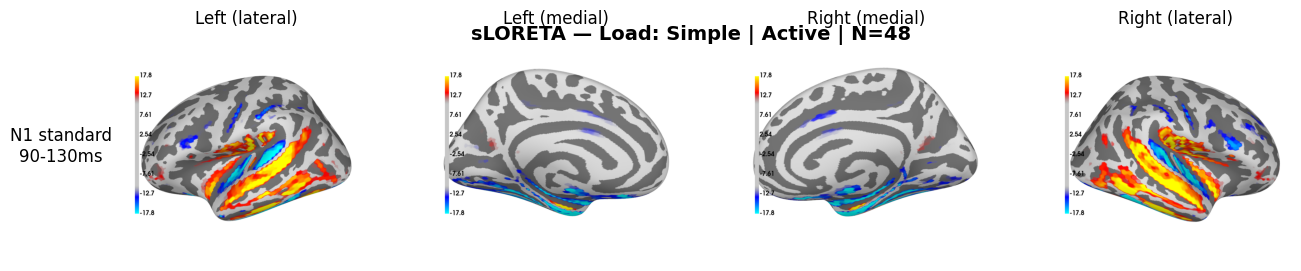

In [20]:
# ==============================================================================
# Plot matrix — all components × 4 views
# ==============================================================================

VIEWS = [
    ("lateral", "lh"),   # outside left
    ("medial",  "lh"),   # inside left
    ("medial",  "rh"),   # inside right
    ("lateral", "rh"),   # outside right
]
n_comp = len(stcs)
n_cols = len(VIEWS)

fig = plt.figure(figsize=(n_cols * 4, n_comp * 3))
gs  = gridspec.GridSpec(n_comp, n_cols, figure=fig, hspace=0.1, wspace=0.0)

for row_idx, comp in enumerate(COMPONENTS):
    label = comp["label"]
    if label not in stcs:
        continue
    
    stc = stcs[label]
    
    for col_idx, (view, hemi) in enumerate(VIEWS):
        ax = fig.add_subplot(gs[row_idx, col_idx])
        
        if view == "dorsal":
            brain = stc.plot(
                subject="fsaverage",
                subjects_dir=subjects_dir,
                hemi="both",
                views="dorsal",
                background="white",
                colormap="mne",
                smoothing_steps=5,
                clim=clim,
                time_label=None,
                verbose=False,
            )
        else:
            brain = stc.plot(
                subject="fsaverage",
                subjects_dir=subjects_dir,
                hemi=hemi,
                views=view,
                background="white",
                colormap="mne",
                smoothing_steps=5,
                clim=clim,
                time_label=None,
                verbose=False,
            )

        screenshot = brain.screenshot()
        brain.close()

        ax.imshow(screenshot)
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)

        if col_idx == 0:
            ax.set_ylabel(
                f"{label}\n{int(comp['tmin']*1000)}-{int(comp['tmax']*1000)}ms",
                fontsize=12, rotation=0, labelpad=50, va="center"
            )

fig.suptitle(
    f"sLORETA — Load: Simple | {PARADIGM.capitalize()} | N={n}",
    fontsize=14, fontweight="bold", y=0.90
)

# Column headers
titles = ["Left (lateral)", "Left (medial)", "Right (medial)", "Right (lateral)"]
for col_idx, title in enumerate(titles):
    fig.axes[col_idx].set_title(title, fontsize=12, pad=5)

fname = root_img / f"{DATE_STR}_{PARADIGM}_sloreta_load_simple_all_components_view4_scaledtomax.png"
plt.savefig(fname, dpi=150, bbox_inches="tight")
print(f"Saved -> {fname.name}")
plt.show()


In [22]:
# ==============================================================================
# Individual component plots (optional — for detailed inspection)
# ==============================================================================
clim_str = "clim-pct75-85-95"
for comp in COMPONENTS:
    label = comp["label"]
    if label not in stcs:
        continue
    
    stc = stcs[label]
    tmin_ms = int(comp["tmin"] * 1000)
    tmax_ms = int(comp["tmax"] * 1000)
    
    brain = stc.plot(
        subject="fsaverage",
        subjects_dir=subjects_dir,
        hemi="both",
        views=["lateral", "dorsal"],
        background="white",
        colormap="mne",
        smoothing_steps=5,
        clim = clim,
        time_label=None,
        verbose=False,
    )

    fname_ind = root_img / "indiv" / f"{DATE_STR}_{PARADIGM}_sloreta_{label.replace(' ','_')}_{tmin_ms}-{tmax_ms}ms.png"
    screenshot = brain.screenshot()
    brain.close()

    (root_img / "indiv").mkdir(parents=True, exist_ok=True)
    fig_ind, ax_ind = plt.subplots(figsize=(10, 5))
    ax_ind.imshow(screenshot)
    ax_ind.axis("off")
    ax_ind.set_title(
        f"{label} | {comp['stim']} | {tmin_ms}-{tmax_ms}ms | {PARADIGM.capitalize()} | Simple",
        fontsize=10, fontweight="bold", pad=10
    )
    plt.subplots_adjust(top=0.88)
    fname_ind = root_img / "indiv" / f"{DATE_STR}_{PARADIGM}_sloreta_{label.replace(' ','_')}_{tmin_ms}-{tmax_ms}ms_{clim_str}.png"
    plt.savefig(fname_ind, dpi=150, bbox_inches="tight")
    plt.close()
    print(f"Saved -> {fname_ind.name}")


Saved -> 20261031_active_sloreta_N1_standard_90-130ms_clim-pct75-85-95.png


# Response locked

In [23]:
# ==============================================================================
# Response-locked — Simple | NOCSD | bc-200-100-resp
# ==============================================================================
DATE_RESP = None          # None = latest; or pin, e.g. "20261031"
BC_RESP   = "bc-200-100"

if DATE_RESP is None:
    _r = sorted(input_path_resp.glob(f"*_{PARADIGM}_{n_source}p_cond-simple_resp_{BC_RESP}_NOCSD_raw.pkl"))
    assert _r, f"No response-locked pkl in {input_path_resp}"
    DATE_RESP = _r[-1].name.split("_")[0]
fname_resp = input_path_resp / f"{DATE_RESP}_{PARADIGM}_{n_source}p_cond-simple_resp_{BC_RESP}_NOCSD_raw.pkl"
print(f"Response-locked: {fname_resp.name}")
evokeds_resp = load_pkl(fname_resp)
print(f"Loaded: {list(evokeds_resp.keys())}")



COMPONENTS_RESP = [
    dict(label="P3 response", stim="response", tmin=-0.1, tmax=0.1),
]

Response-locked: 20261031_active_48p_cond-simple_resp_bc-200-100_NOCSD_raw.pkl
Loaded: ['simple_response']


In [24]:
stcs_resp = run_sloreta(evokeds_resp, COMPONENTS_RESP)
print(f"Computed {len(stcs_resp)} response-locked source estimates.")

Processing: P3 response...
Identifying common channels ...
Created an SSP operator (subspace dimension = 1)
1 projection items activated
SSP projectors applied...
  Done — peak: 41.6513
Computed 1 response-locked source estimates.


In [25]:
stcs_current  = stcs_resp
comps_current = COMPONENTS_RESP
suffix        = "resp"

In [26]:
all_vals_resp  = np.concatenate([np.abs(stc.data.flatten()) for stc in stcs_resp.values()])
global_75_resp = np.percentile(all_vals_resp, 75)
global_85_resp = np.percentile(all_vals_resp, 85)
global_95_resp = np.percentile(all_vals_resp, 95)
clim_resp      = dict(kind="value", pos_lims=[global_75_resp, global_85_resp, global_95_resp])
print(f"Global clim resp: {global_75_resp:.2f} / {global_85_resp:.2f} / {global_95_resp:.2f}")

Global clim resp: 15.89 / 19.35 / 25.50


Saved -> 20261031_active_sloreta_load_simple_resp_all_components_views4_scaledtomax.png


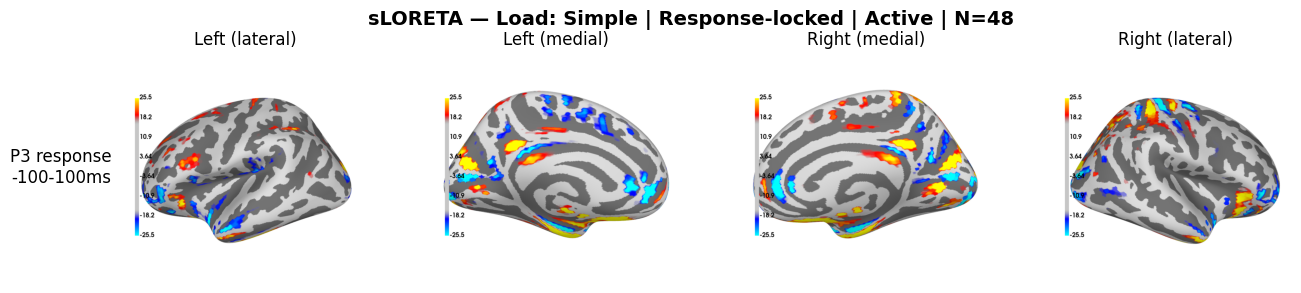

In [27]:
# ==============================================================================
# Plot matrix — all components × 4 views
# ==============================================================================

VIEWS = [
    ("lateral", "lh"),   # outside left
    ("medial",  "lh"),   # inside left
    ("medial",  "rh"),   # inside right
    ("lateral", "rh"),   # outside right
]
n_comp = len(stcs_resp)
n_cols = len(VIEWS)

fig = plt.figure(figsize=(n_cols * 4, n_comp * 3))
gs  = gridspec.GridSpec(n_comp, n_cols, figure=fig, hspace=0.1, wspace=0.0)

for row_idx, comp in enumerate(COMPONENTS_RESP):
    label = comp["label"]
    if label not in stcs_resp:
        continue
    
    stc = stcs_resp[label]
    
    for col_idx, (view, hemi) in enumerate(VIEWS):
        ax = fig.add_subplot(gs[row_idx, col_idx])
        
        if view == "dorsal":
            brain = stc.plot(
                subject="fsaverage",
                subjects_dir=subjects_dir,
                hemi="both",
                views="dorsal",
                background="white",
                colormap="mne",
                smoothing_steps=5,
                clim=clim_resp,
                time_label=None,
                verbose=False,
            )
        else:
            brain = stc.plot(
                subject="fsaverage",
                subjects_dir=subjects_dir,
                hemi=hemi,
                views=view,
                background="white",
                smoothing_steps=5,
                colormap="mne",
                clim=clim_resp,
                time_label=None,
                verbose=False,
            )

        screenshot = brain.screenshot()
        brain.close()

        ax.imshow(screenshot)
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_visible(False)

        if col_idx == 0:
            ax.set_ylabel(
                f"{label}\n{int(comp['tmin']*1000)}-{int(comp['tmax']*1000)}ms",
                fontsize=12, rotation=0, labelpad=50, va="center"
            )

fig.suptitle(
    f"sLORETA — Load: Simple | Response-locked | {PARADIGM.capitalize()} | N={n}",
    fontsize=14, fontweight="bold", y=1.02
)

# Column headers
titles = ["Left (lateral)", "Left (medial)", "Right (medial)", "Right (lateral)"]
for col_idx, title in enumerate(titles):
    fig.axes[col_idx].set_title(title, fontsize=12, pad=5)


fname = root_img / f"{DATE_STR}_{PARADIGM}_sloreta_load_simple_resp_all_components_views4_scaledtomax.png"
plt.savefig(fname, dpi=150, bbox_inches="tight")
print(f"Saved -> {fname.name}")
plt.show()
